Analyse des préférences et comportements d'investissement
Objectif : explorer les préférences d'investissement des répondants et identifier des profils présentant des comportements similaires à partir des scores renseignés pour sept catégories de placement.

Important : le fichier fourni contient 40 répondants et 24 variables. Il s'agit d'une enquête transversale, et non d'une série chronologique de rendements boursiers. Le travail ci-dessous est donc une analyse exploratoire complétée par une segmentation non supervisée. Il ne permet pas de prédire les rendements futurs ni de démontrer une relation causale.

Méthode principale : K-Means, avec standardisation des sept variables numériques relatives aux catégories d'investissement.

Graine aléatoire : 42.

1. Problématique et objectif
Les investisseurs ne privilégient pas tous les mêmes catégories de placement. L'âge, les objectifs d'épargne, la perception du risque et les attentes de rendement peuvent accompagner des préférences différentes.

Problématique : peut-on identifier, à partir des scores déclarés pour sept catégories de placement, des groupes de répondants présentant des profils de préférences similaires ?

Tâche : apprentissage non supervisé (segmentation / clustering).

Objectif mesurable fixé avant l'analyse : comparer plusieurs nombres de groupes (k = 2 à 5) à l'aide du coefficient de silhouette. Nous retiendrons une solution qui combine une silhouette satisfaisante et des groupes suffisamment interprétables, sans choisir automatiquement le k qui maximise le score.

Pourquoi ne pas faire une classification supervisée ? Le fichier ne fournit pas de cible de décision clairement définie pour cette question et ne contient que 40 observations. Certaines catégories sont très peu représentées. Une classification aurait donc un risque élevé d'évaluation instable.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## In this kernel we will analyse the finance data which was collected and try to bring out some infereneces from it
![PIC](https://cdn.datafloq.com/cache/blog_pictures/878x531/why-future-finance-data-science.jpg)

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# Any results you write to the current directory are saved as output.

/kaggle/input/finance-data/Original_data.csv
/kaggle/input/finance-data/Finance_data.csv


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style('darkgrid')

In [3]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Test_FIN2/Finance_data.csv")

In [ ]:
df.head()

,gender,age,Investment_Avenues,Mutual_Funds,Equity_Market,Debentures,Government_Bonds,Fixed_Deposits,PPF,Gold,...,Duration,Invest_Monitor,Expect,Avenue,What are your savings objectives?,Reason_Equity,Reason_Mutual,Reason_Bonds,Reason_FD,Source
0,Female,34,Yes,1,2,5,3,7,6,4,...,1-3 years,Monthly,20%-30%,Mutual Fund,Retirement Plan,Capital Appreciation,Better Returns,Safe Investment,Fixed Returns,Newspapers and Magazines
1,Female,23,Yes,4,3,2,1,5,6,7,...,More than 5 years,Weekly,20%-30%,Mutual Fund,Health Care,Dividend,Better Returns,Safe Investment,High Interest Rates,Financial Consultants
2,Male,30,Yes,3,6,4,2,5,1,7,...,3-5 years,Daily,20%-30%,Equity,Retirement Plan,Capital Appreciation,Tax Benefits,Assured Returns,Fixed Returns,Television
3,Male,22,Yes,2,1,3,7,6,4,5,...,Less than 1 year,Daily,10%-20%,Equity,Retirement Plan,Dividend,Fund Diversification,Tax Incentives,High Interest Rates,Internet
4,Female,24,No,2,1,3,6,4,5,7,...,Less than 1 year,Daily,20%-30%,Equity,Retirement Plan,Capital Appreciation,Better Returns,Safe Investment,Risk Free,Internet


In [6]:
df.drop(['Mutual_Funds', 'Equity_Market',
       'Debentures', 'Government_Bonds', 'Fixed_Deposits', 'PPF', 'Gold'],axis=1,inplace=True, errors='ignore')

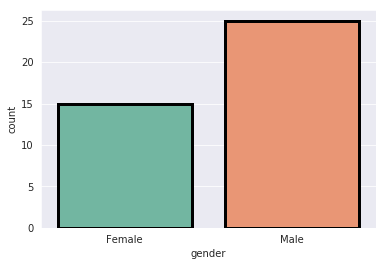

In [ ]:
# First we will see Gender of our respondenets
sns.countplot(df['gender'],linewidth=3,palette="Set2",edgecolor='black')
plt.show()

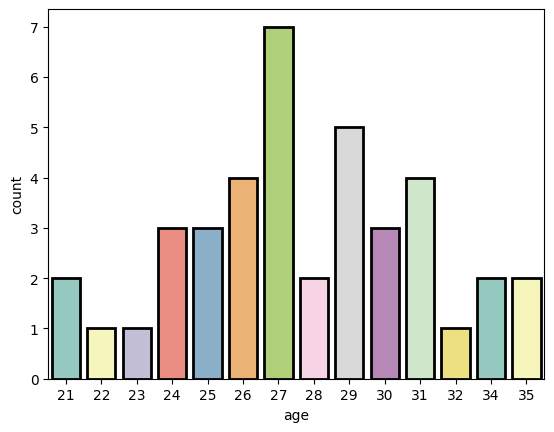

In [10]:
# Now we will see Age of our respondents
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=df['age'], hue=df['age'], palette="Set3", linewidth=2, edgecolor='black', legend=False)
plt.show()

We can see from the above graph that most of our respondents were in the ages 24-31 and we will look further
their habits in the finanace field

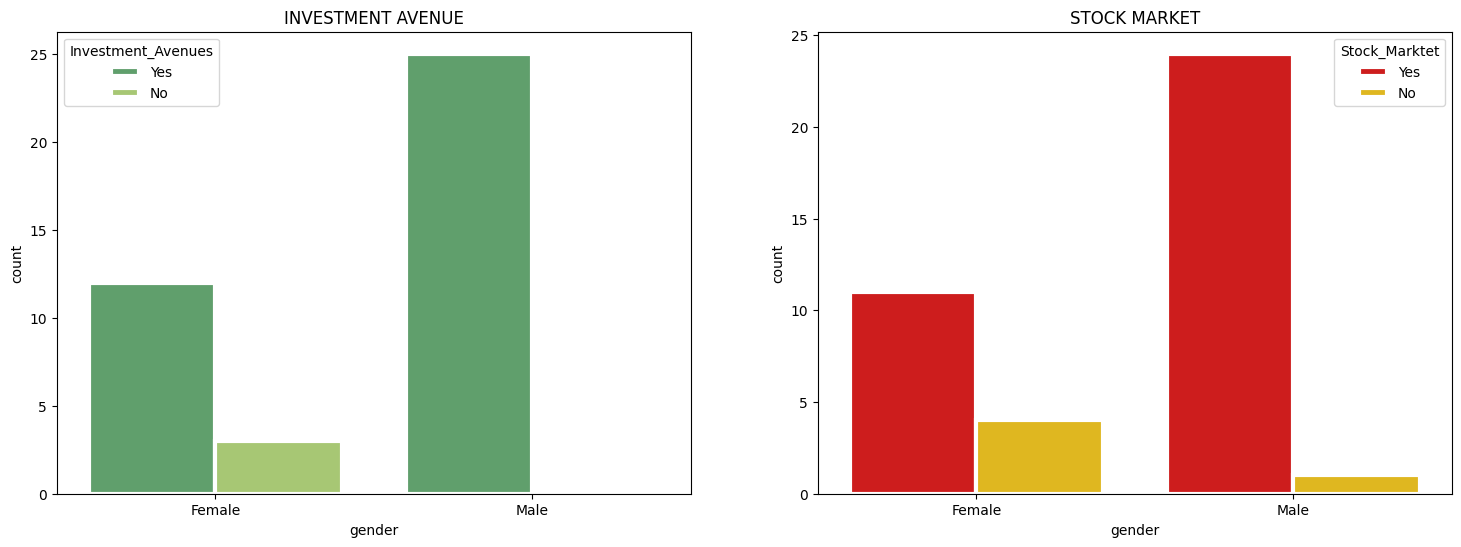

In [11]:
# Now lets see these same factors of INVESTMENT_AVENUE and STOCK_MARKET with gender

plt.figure(figsize=(18,6))
plt.subplot(1, 2, 1)
sns.countplot(x=df['gender'],hue=df['Investment_Avenues'],palette='summer',linewidth=3,edgecolor='white')
plt.title('INVESTMENT AVENUE')
plt.subplot(1, 2, 2)
sns.countplot(x=df['gender'],hue=df['Stock_Marktet'],palette='hot',linewidth=3,edgecolor='white')
plt.title('STOCK MARKET')
plt.show()


# Mostly females dont invest or go to stocks

/tmp/ipykernel_654/3451883792.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['Factor'],palette='coolwarm',linewidth=2,edgecolor='black')


<Axes: xlabel='Factor', ylabel='count'>

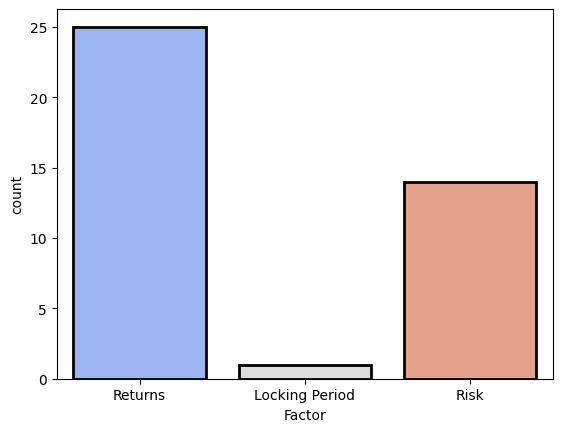

In [12]:
# Factors affecting Investing
sns.countplot(x=df['Factor'],palette='coolwarm',linewidth=2,edgecolor='black')

# Returns is the most influential Factor considered while investing which is followed by risk

The above trend shows us that people are less worried about risks involved and more worried about the money which they will get back

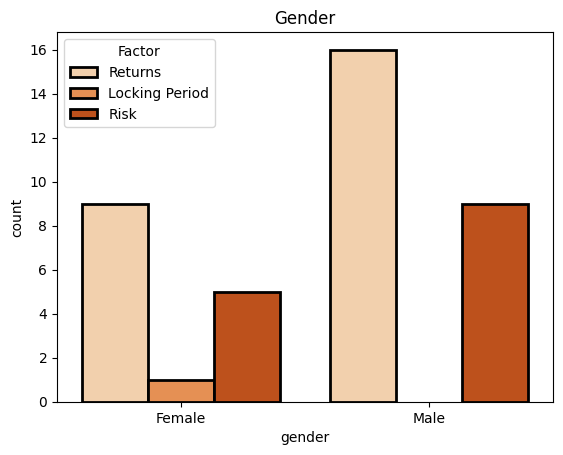

In [13]:
# Lets see which Age groups take the highest risk
sns.countplot(x=df['gender'],hue=df['Factor'],palette='Oranges',linewidth=2,edgecolor='black')
plt.title('Gender')
plt.show()


We can see that high number of males are dependent on Returns

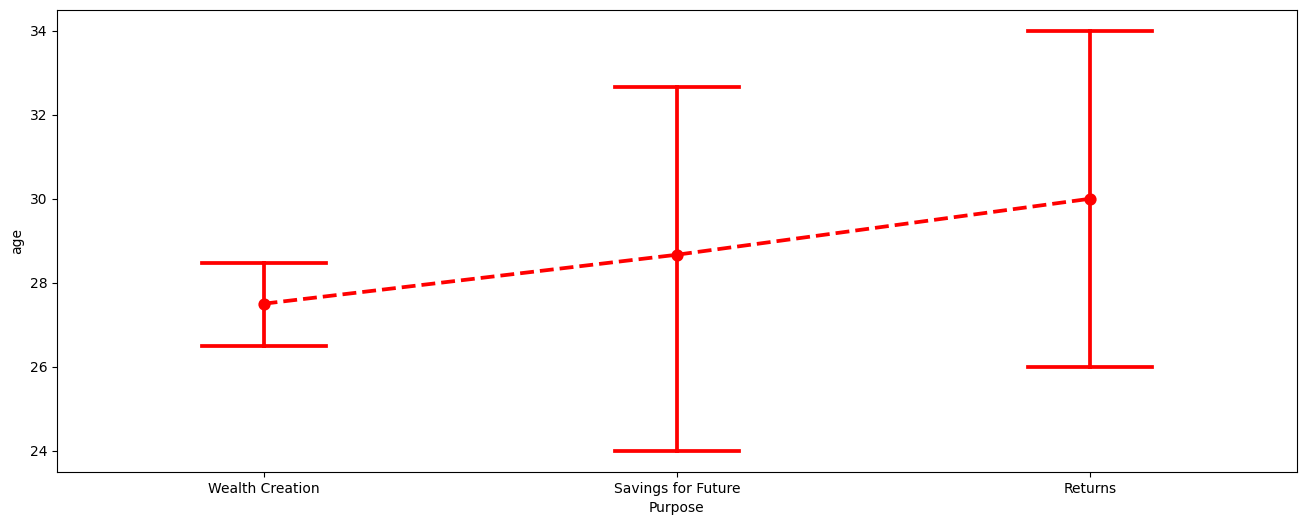

In [14]:
plt.figure(figsize=(16,6))
sns.pointplot(x="Purpose",y='age',data=df,linestyles="--",capsize=.3,color='Red')
plt.show()

From the above plot it is clear that as people grow older they are more inclined towards Returns and people at young age look more for wealth creation

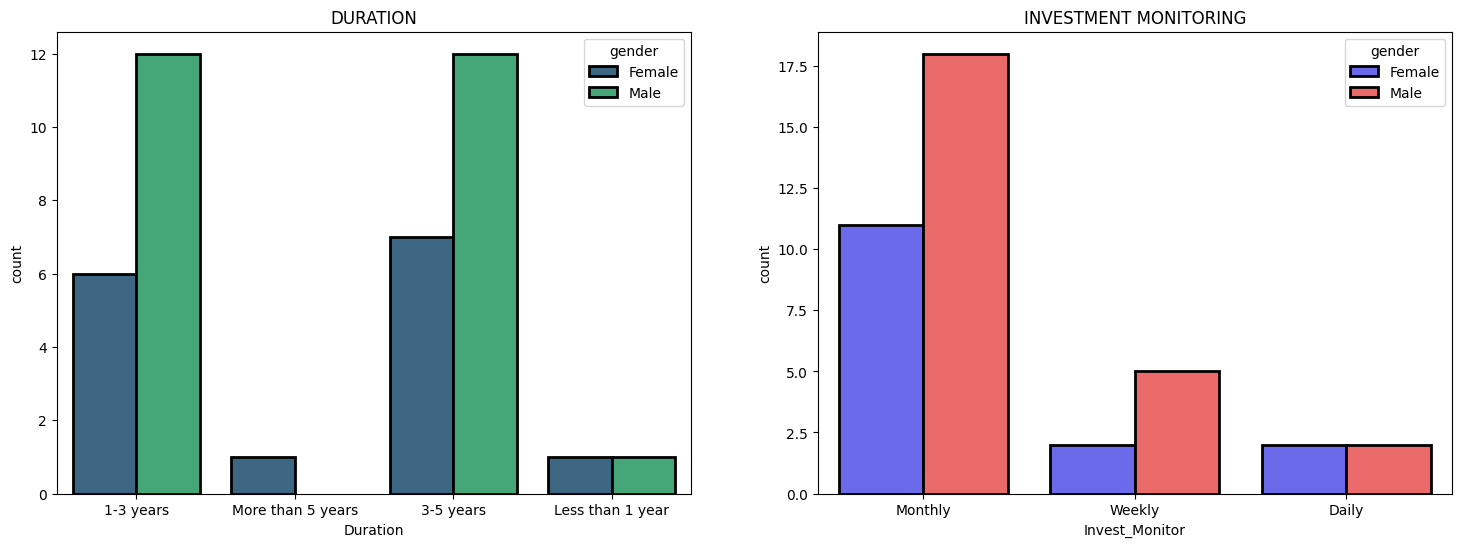

In [15]:
# Now lets see these same factors of Duration and Invest_monitor with gender

plt.figure(figsize=(18,6))
plt.subplot(1, 2, 1)
sns.countplot(hue=df['gender'],x=df['Duration'],palette='viridis',linewidth=2,edgecolor='black')
plt.title('DURATION')
plt.subplot(1, 2, 2)
sns.countplot(hue=df['gender'],x=df['Invest_Monitor'],palette='seismic',linewidth=2,edgecolor='black')
plt.title('INVESTMENT MONITORING')
plt.show()

#Below graphs show us that most of the people invest from 1-5 Years and monitor their investments mostly monthly

# **More to come, Stay tuned for the updates**